# Tests: IDE replication + fingerprinting vs. code distance

Validates the modules in this folder (`surface_memory`, `decoder`, `extrapolation`, `fingerprint_analysis`) and runs a small end-to-end demo.

**Kernel:** use `STIM-QC (.venv)` (the virtualenv in this folder).

Sections:
1. Circuit correctness (noiseless = silent, circuit distance = d)
2. Device/chip model (validation, same chip across distances)
3. Extrapolation maths (synthetic data with known answer)
4. Fingerprinting statistics
5. Physics check: logical error rate falls with d below threshold
6. Demo: IDE fit + fingerprinting plots (quick shot budget)
7. Load results of the full `run_replication.py` run, if present

In [12]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import stim

from decoder import collect_logical, detector_firing_rates
from extrapolation import fit_ide, richardson, single_exp
from fingerprint_analysis import (
    logical_distinguishability,
    shots_to_distinguish,
    syndrome_shots_needed,
)
from surface_memory import DeviceNoise, noiseless_memory_circuit, noisy_memory_circuit

WORKERS = 4
print("stim", stim.__version__)

stim 1.16.0


## 1. Circuit correctness

In [13]:
# 1a. A p = 0 device must never fire a detector nor flip the logical observable.
for d in (3, 5):
    c = noisy_memory_circuit(d, DeviceNoise("ideal", p=0.0))
    dets, obs = c.compile_detector_sampler(seed=1).sample(2_000, separate_observables=True)
    assert not dets.any() and not obs.any(), f"noiseless d={d} circuit is not silent"
print("PASS 1a: noiseless circuits are deterministic")

# 1b. 3d rounds by default, and noise insertion keeps the detector structure.
for d in (3, 5, 7):
    noisy = noisy_memory_circuit(d, DeviceNoise("u", p=0.002))
    clean = noiseless_memory_circuit(d, rounds=3 * d)
    assert noisy.num_detectors == clean.num_detectors
    assert noisy.num_observables == 1
print("PASS 1b: 3d rounds, detector count preserved")

# 1c. Circuit-level distance equals the code distance (uniform and inhomogeneous).
for d in (3, 5, 7):
    for dev in (DeviceNoise("u", 0.002), DeviceNoise("chip", 0.002, 0.3, seed=1)):
        found = len(noisy_memory_circuit(d, dev).shortest_graphlike_error())
        assert found == d, f"{dev.name}: expected distance {d}, got {found}"
print("PASS 1c: circuit distance == d")

PASS 1a: noiseless circuits are deterministic
PASS 1b: 3d rounds, detector count preserved
PASS 1c: circuit distance == d


## 2. Device / chip model

PASS 2a: invalid devices rejected
PASS 2b: 17 shared qubits carry identical rates at d=3 and d=5
PASS 2c: chips differ (mean rate 2.82e-03 vs 2.78e-03)


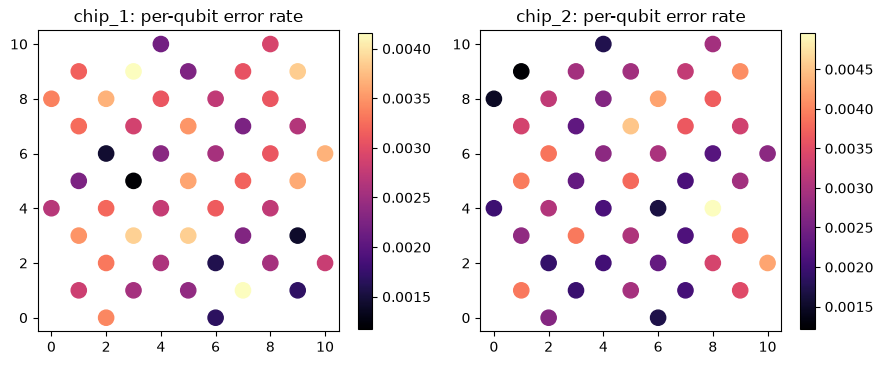

In [14]:
# 2a. Input validation.
for bad in (dict(p=-0.1), dict(p=0.9), dict(p=0.001, inhomogeneity=-1.0)):
    try:
        DeviceNoise("bad", **bad)
    except ValueError:
        continue
    raise AssertionError(f"DeviceNoise accepted invalid args {bad}")
print("PASS 2a: invalid devices rejected")

# 2b. Same chip keeps the same qubit rates when the patch grows (d=3 -> d=5).
#     Read the X_ERROR rates actually inserted in each circuit, keyed by coordinate.
def inserted_rates(circuit: stim.Circuit) -> dict:
    coords = circuit.get_final_qubit_coordinates()
    out = {}
    for inst in circuit.flattened():
        if inst.name == "X_ERROR":
            for t in inst.targets_copy():
                out[tuple(coords[t.value])] = inst.gate_args_copy()[0]
    return out

chip = DeviceNoise("chip_1", 0.003, 0.3, seed=1)
rates3 = inserted_rates(noisy_memory_circuit(3, chip))
rates5 = inserted_rates(noisy_memory_circuit(5, chip))
shared = set(rates3) & set(rates5)
assert len(shared) > 0
assert all(math.isclose(rates3[c], rates5[c]) for c in shared)
assert len(set(rates5.values())) > 1, "inhomogeneous chip should have varied rates"
print(f"PASS 2b: {len(shared)} shared qubits carry identical rates at d=3 and d=5")
c5 = noiseless_memory_circuit(5, 1).get_final_qubit_coordinates()

# 2c. Different seeds = different chips; uniform device = constant p.
other = DeviceNoise("chip_2", 0.003, 0.3, seed=2)
r1 = np.array([chip.qubit_error_rate(c) for c in shared])
r2 = np.array([other.qubit_error_rate(c) for c in shared])
assert not np.allclose(r1, r2)
assert all(DeviceNoise("u", 0.003).qubit_error_rate(c) == 0.003 for c in shared)
print(f"PASS 2c: chips differ (mean rate {r1.mean():.2e} vs {r2.mean():.2e})")

# Visualise the two chips' qubit error maps on the d=5 patch.
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, dev in zip(axes, (chip, other)):
    xy = np.array(list(c5.values()))
    rates = [dev.qubit_error_rate(tuple(v)) for v in c5.values()]
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=rates, cmap="magma", s=120)
    ax.set_title(f"{dev.name}: per-qubit error rate")
    ax.set_aspect("equal")
    fig.colorbar(sc, ax=ax, shrink=0.8)
plt.tight_layout()

## 3. Extrapolation maths (known answers)

In [15]:
# 3a. The IDE fit recovers A from noisy synthetic data A - B exp(-C d).
rng = np.random.default_rng(0)
d = np.array([3, 5, 7, 9, 11], dtype=float)
true_a, true_b, true_c = 0.999, 0.5, 0.45
sigma = np.full_like(d, 2e-4)
y = single_exp(d, true_a, true_b, true_c) + rng.normal(0, sigma)
fit = fit_ide(d, y, sigma, "single")
assert abs(fit.extrapolated - true_a) < 5 * max(fit.extrapolated_std, 2e-4), fit
print(f"PASS 3a: A_fit = {fit.extrapolated:.5f} +/- {fit.extrapolated_std:.1e} (true {true_a})")

# 3b. Richardson is exact for a degree-(m-1) polynomial in 1/d.
lam = 1 / d[:3]
assert abs(richardson(d[:3], 0.7 + 0.3 * lam - 0.8 * lam**2) - 0.7) < 1e-12
print("PASS 3b: Richardson exact on polynomial data")

# 3c. Too few points / unknown ansatz are rejected.
for args in ((d[:2], y[:2], sigma[:2], "single"), (d[:4], y[:4], sigma[:4], "double"), (d, y, sigma, "cubic")):
    try:
        fit_ide(*args)
    except ValueError:
        continue
    raise AssertionError(f"fit_ide accepted {args[-1]} with {len(args[0])} points")
print("PASS 3c: invalid fits rejected")

PASS 3a: A_fit = 0.99894 +/- 2.2e-04 (true 0.999)
PASS 3b: Richardson exact on polynomial data
PASS 3c: invalid fits rejected


## 4. Fingerprinting statistics

In [16]:
# 4a. Identical devices are indistinguishable; smaller gaps cost more shots.
assert shots_to_distinguish(0.01, 0.01) == math.inf
assert shots_to_distinguish(0.010, 0.012) > shots_to_distinguish(0.010, 0.020)
print("PASS 4a: two-proportion sample size behaves")

# 4b. Key scaling: at a FIXED relative difference (pB = 1.2 pA), the cost grows ~ 1/pA.
#     This is exactly what larger d does: pL drops exponentially => cost rises exponentially.
pa = np.logspace(-1, -6, 6)
cost = np.array([shots_to_distinguish(p, 1.2 * p) for p in pa])
assert np.all(np.diff(cost) > 0)
slope = np.polyfit(np.log10(pa), np.log10(cost), 1)[0]
assert -1.1 < slope < -0.9, slope
print(f"PASS 4b: shots ~ pL^{slope:.2f} at fixed ratio")

# 4c. Syndrome metric: identical rate vectors -> inf, different -> finite.
ra = np.array([0.01, 0.02, 0.03])
assert syndrome_shots_needed(ra, ra) == math.inf
assert math.isfinite(syndrome_shots_needed(ra, ra * 1.1))
print("PASS 4c: syndrome metric behaves")

PASS 4a: two-proportion sample size behaves
PASS 4b: shots ~ pL^-1.01 at fixed ratio
PASS 4c: syndrome metric behaves


## 5. Physics check: below threshold, p_L falls with d
(Small shot budget, ~30 s.)

In [17]:
res = collect_logical([DeviceNoise("p=0.003", 0.003)], [3, 5, 7], max_shots=100_000, max_errors=1_000, num_workers=WORKERS)
for r in res:
    print(f"d={r.distance}: shots={r.shots:>7}  p_L={r.logical_error_rate:.3e}  <Z>={r.expectation:.4f} +/- {r.expectation_std:.1e}")
ler = [r.logical_error_rate for r in res]
assert ler[0] > ler[1] > ler[2], "logical error rate should decrease with d below threshold"
print(f"PASS 5: suppression factor Lambda ~ {ler[0] / ler[1]:.2f}, {ler[1] / ler[2]:.2f}")

d=3: shots=  17681  p_L=5.786e-02  <Z>=0.8843 +/- 3.5e-03
d=5: shots=  27170  p_L=4.380e-02  <Z>=0.9124 +/- 2.5e-03
d=7: shots=  45124  p_L=2.615e-02  <Z>=0.9477 +/- 1.5e-03
PASS 5: suppression factor Lambda ~ 1.32, 1.67


## 6. Demo (quick budget)
### 6a. IDE: fit d = 3, 5, 7 and extrapolate to d -> infinity

p=0.003: raw err(d=7) = 5.29e-02 | IDE A = 1.50000 (err 5.00e-01) | held-out d=9: measured 0.9693, predicted 0.9762
p=0.004: raw err(d=7) = 1.50e-01 | IDE A = 1.50000 (err 5.00e-01) | held-out d=9: measured 0.8875, predicted 0.8714


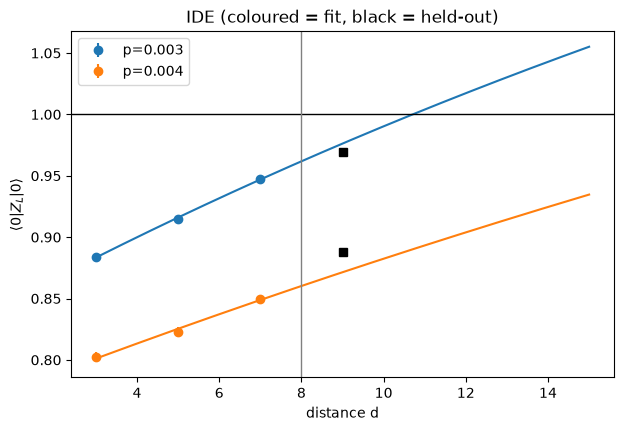

In [18]:
P_VALUES, FIT_DS, REF_DS = [0.003, 0.004], [3, 5, 7], [9]
devices = [DeviceNoise(f"p={p}", p) for p in P_VALUES]
ide_res = collect_logical(devices, FIT_DS + REF_DS, max_shots=100_000, max_errors=2_000, num_workers=WORKERS)

fig, ax = plt.subplots(figsize=(7, 4.5))
dd = np.linspace(3, 15, 200)
for dev, color in zip(devices, ("tab:blue", "tab:orange")):
    rs = [r for r in ide_res if r.device == dev.name]
    fr = [r for r in rs if r.distance in FIT_DS]
    hr = [r for r in rs if r.distance in REF_DS]
    x = np.array([r.distance for r in fr], float)
    e = np.array([r.expectation for r in fr])
    s = np.array([r.expectation_std for r in fr])
    f = fit_ide(x, e, s)
    pred = f.predict(np.array([r.distance for r in hr]))
    print(f"{dev.name}: raw err(d={FIT_DS[-1]}) = {1 - e[-1]:.2e} | IDE A = {f.extrapolated:.5f} "
          f"(err {abs(1 - f.extrapolated):.2e}) | held-out d={REF_DS[0]}: measured {hr[0].expectation:.4f}, predicted {pred[0]:.4f}")
    ax.errorbar(x, e, s, fmt="o", color=color, label=dev.name)
    ax.errorbar([r.distance for r in hr], [r.expectation for r in hr], [r.expectation_std for r in hr], fmt="s", color="k")
    ax.plot(dd, f.predict(dd), color=color)
ax.axhline(1, color="k", lw=1)
ax.axvline(FIT_DS[-1] + 1, color="grey", lw=1)
ax.set(xlabel="distance d", ylabel=r"$\langle 0|Z_L|0\rangle$", title="IDE (coloured = fit, black = held-out)")
ax.legend();

### 6b. Fingerprinting: two chips with the same spec (p = 0.003, sigma = 0.3)
Logical-only view vs. raw-syndrome view.

  d       pL_1       pL_2        TVD   N*_logical  N*_syndrome
  3   5.38e-02   5.80e-02   4.13e-03     9.18e+04          226
  5   3.64e-02   4.26e-02   6.24e-03      2.9e+04         15.4
  7   2.21e-02   2.82e-02   6.13e-03     1.94e+04         5.77
PASS 6b: syndrome-level fingerprint survives (and sharpens) with d


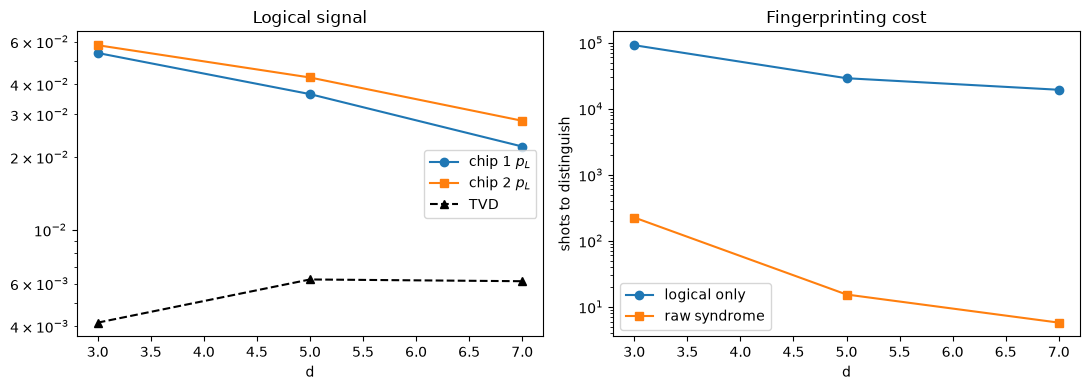

In [19]:
DS = [3, 5, 7]
chip_1 = DeviceNoise("chip_1", 0.003, 0.3, seed=1)
chip_2 = DeviceNoise("chip_2", 0.003, 0.3, seed=2)
fp = collect_logical([chip_1, chip_2], DS, max_shots=200_000, max_errors=5_000, num_workers=WORKERS)
logical = logical_distinguishability([r for r in fp if r.device == "chip_1"], [r for r in fp if r.device == "chip_2"])
syn = [syndrome_shots_needed(detector_firing_rates(chip_1, d, 20_000, seed=11),
                             detector_firing_rates(chip_2, d, 20_000, seed=22)) for d in DS]

print(f"{'d':>3} {'pL_1':>10} {'pL_2':>10} {'TVD':>10} {'N*_logical':>12} {'N*_syndrome':>12}")
for x, n in zip(logical, syn):
    print(f"{x.distance:>3} {x.p_a:>10.2e} {x.p_b:>10.2e} {x.tvd:>10.2e} {x.shots_needed:>12.3g} {n:>12.3g}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.semilogy(DS, [x.p_a for x in logical], "o-", label="chip 1 $p_L$")
a1.semilogy(DS, [x.p_b for x in logical], "s-", label="chip 2 $p_L$")
a1.semilogy(DS, [x.tvd for x in logical], "k^--", label="TVD")
a1.set(xlabel="d", title="Logical signal"); a1.legend()
a2.semilogy(DS, [x.shots_needed for x in logical], "o-", label="logical only")
a2.semilogy(DS, syn, "s-", label="raw syndrome")
a2.set(xlabel="d", ylabel="shots to distinguish", title="Fingerprinting cost"); a2.legend()
plt.tight_layout()

assert all(math.isfinite(n) for n in syn) and syn[-1] < syn[0], "syndrome view should get easier with d"
print("PASS 6b: syndrome-level fingerprint survives (and sharpens) with d")

> **Caveat:** at this shot budget the logical TVD at d >= 5 is close to the shot-noise floor, so `N*_logical` is noisy. The full run (`run_replication.py`, 2M shots) gives cleaner numbers - see below.

## 7. Full-run results (if `run_replication.py` has finished)

--- ide_summary.csv ---
          p   E_raw(d=9)      err_raw        E_IDE      err_IDE    E_IDE_std  E_Richardso  err_Richard
      0.002     0.995834  0.004166000  1.003809306  0.003809306  0.000297582  0.998002453  0.001997546
      0.003  0.969061174  0.030938825  1.053872348  0.053872348  0.007559961  1.065928082  0.065928082
      0.004  0.883648867  0.116351132  1.499999999  0.499999999  0.599402144  1.072497389  0.072497389
      0.005  0.717173429  0.282826570  0.711664995  0.288335004  0.001096956  0.876546006  0.123453993
--- fingerprint.csv ---
          d     pL_chip1     pL_chip2          TVD        ratio  shots_neede  shots_neede
          3  0.057293139  0.050257794  0.007035345  1.139985162  30590.56405  102.5981345
          5  0.039423337  0.041289387  0.001866050  1.047333660  330968.6502  19.66317524
          7  0.022661099  0.024397933  0.001736834  1.076643876  226655.1305  6.368181630
          9      0.01244       0.0143  0.001860000  1.149517684  113465.9138 

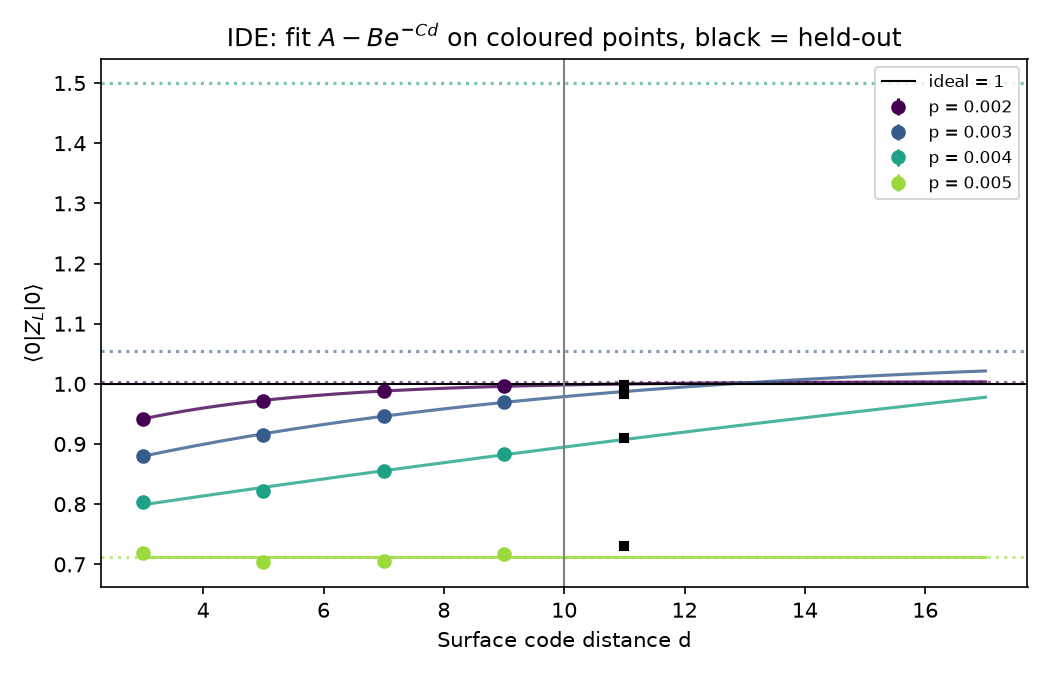

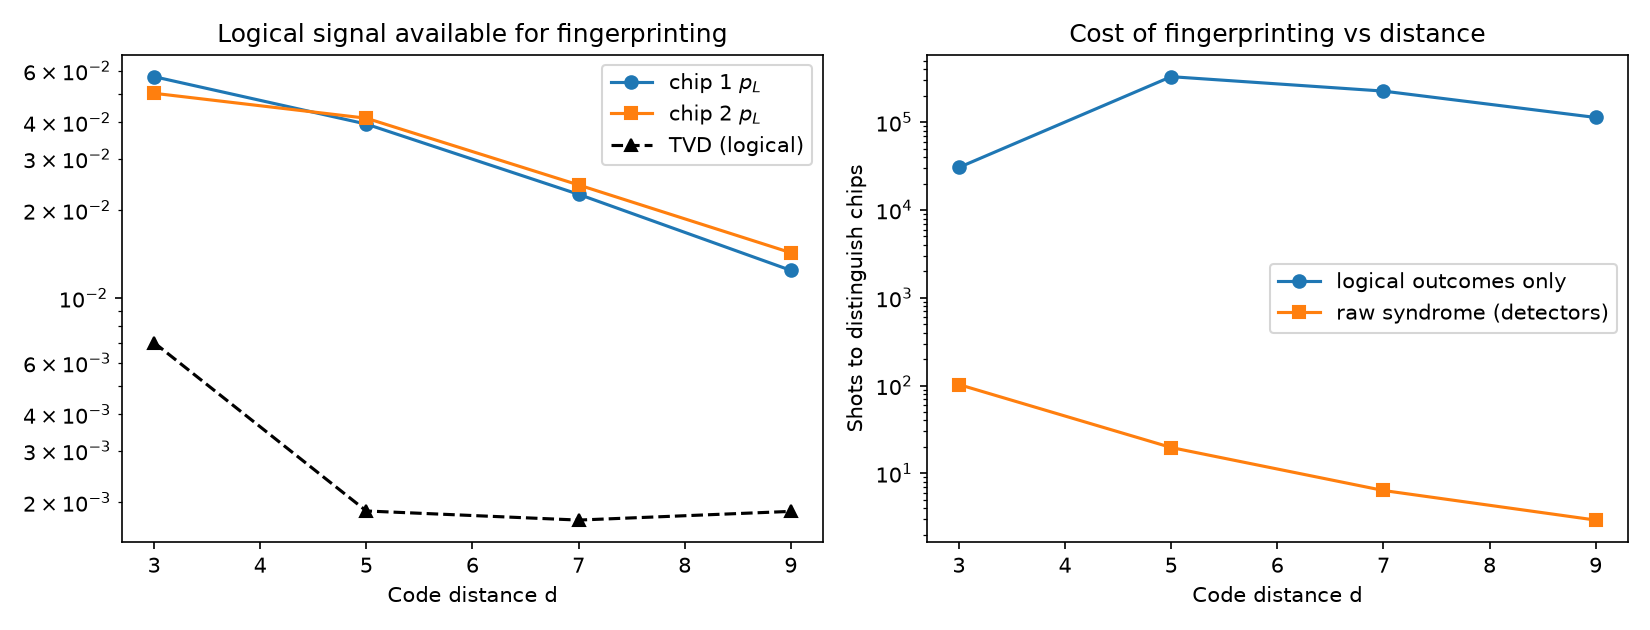

In [20]:
import csv
from IPython.display import Image, display

for name in ("ide_summary.csv", "fingerprint.csv"):
    path = Path("results") / name
    if path.exists():
        print(f"--- {name} ---")
        for row in csv.reader(path.open()):
            print("  ".join(f"{c[:11]:>11}" for c in row))
for png in ("ide_expectation_vs_distance.png", "fingerprint_vs_distance.png"):
    path = Path("figures") / png
    if path.exists():
        display(Image(filename=str(path)))